# Phasor scratchpad

Working space for the phasor math in Chapter 3. Phasors are Python complex numbers: build them with `P(magnitude, degrees)`, add and subtract them directly, and print them with `show(...)`.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- phasor helpers ----------
def P(mag, deg):
    """Phasor from polar form: P(120, -120) means 120 V at -120 degrees."""
    return mag * np.exp(1j * np.deg2rad(deg))

def polar(z, digits=2):
    """Complex number -> '207.85 ∠ 30.00°' (angle in -180..180)."""
    return f"{abs(z):.{digits}f} ∠ {np.rad2deg(np.angle(z)):.{digits}f}°"

def show(**phasors):
    """Print phasors in polar and rectangular form: show(V_AB=V_AB, V_BN=V_BN)."""
    for name, z in phasors.items():
        print(f"{name:>6} = {polar(z):>20}    ({z.real:+9.2f} {z.imag:+9.2f}j)")

def plot_phasors(from_n=None, tip_to_tip=None, title=None, ax=None):
    """Draw a phasor diagram.
    from_n:     dict name -> phasor, drawn as arrows from the neutral (origin).
    tip_to_tip: dict name -> (start, end), drawn dashed from one tip to another,
                e.g. {"V_AB": (V_BN, V_AN)} draws V_AB from B's tip to A's tip.
    """
    from_n = from_n or {}
    tip_to_tip = tip_to_tip or {}
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 5))
    pts = [0j] + list(from_n.values()) + [p for se in tip_to_tip.values() for p in se]
    for name, z in from_n.items():
        ax.annotate("", xy=(z.real, z.imag), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", lw=1.6, color="tab:green"))
        ax.text(z.real * 1.08, z.imag * 1.08, name, ha="center", va="center")
    for name, (s, e) in tip_to_tip.items():
        ax.annotate("", xy=(e.real, e.imag), xytext=(s.real, s.imag),
                    arrowprops=dict(arrowstyle="-|>", lw=1.4, ls="--", color="tab:orange"))
        m = (s + e) / 2
        ax.text(m.real, m.imag, f"  {name}", color="tab:orange", ha="left", va="center")
    ax.plot(0, 0, "ko", ms=4)
    ax.text(0, 0, "  N", va="top")
    r = max(abs(p) for p in pts) * 1.25 or 1
    ax.set_xlim(-r, r); ax.set_ylim(-r, r)
    ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
    ax.set_xlabel("Real (V)"); ax.set_ylabel("Imaginary (V)")
    if title: ax.set_title(title)
    return ax

def kirchhoff_check(*line_to_line, tol=1e-6):
    """Line-to-line voltages around the loop must sum to zero."""
    s = sum(line_to_line)
    print("sum =", polar(s), "->", "OK" if abs(s) < tol else "NOT ZERO: check your phasors")


## Worked example: 120/208Y

This should print V_AB = 207.85 ∠ 30.00° and pass the Kirchhoff check.

  V_AN =       120.00 ∠ 0.00°    (  +120.00     +0.00j)
  V_BN =    120.00 ∠ -120.00°    (   -60.00   -103.92j)
  V_CN =     120.00 ∠ 120.00°    (   -60.00   +103.92j)
  V_AB =      207.85 ∠ 30.00°    (  +180.00   +103.92j)
  V_BC =     207.85 ∠ -90.00°    (    +0.00   -207.85j)
  V_CA =     207.85 ∠ 150.00°    (  -180.00   +103.92j)
sum = 0.00 ∠ 0.00° -> OK


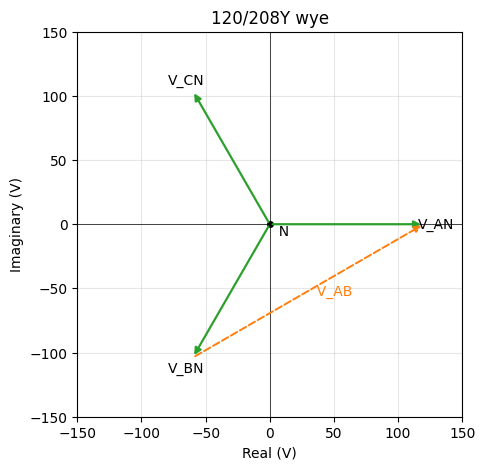

In [ ]:
# Worked example: 120/208Y (wye). Check the helpers reproduce the hand result.
V_AN = P(120, 0)
V_BN = P(120, -120)
V_CN = P(120, 120)

V_AB = V_AN - V_BN
V_BC = V_BN - V_CN
V_CA = V_CN - V_AN

show(V_AN=V_AN, V_BN=V_BN, V_CN=V_CN, V_AB=V_AB, V_BC=V_BC, V_CA=V_CA)
kirchhoff_check(V_AB, V_BC, V_CA)
plot_phasors(from_n={"V_AN": V_AN, "V_BN": V_BN, "V_CN": V_CN},
             tip_to_tip={"V_AB": (V_BN, V_AN)},
             title="120/208Y wye");


## Your turn: centre-tapped delta

Work through the four steps. The Kirchhoff check and the plot tell you whether you're consistent.

  V_CN =    120.00 ∠ -180.00°    (  -120.00     -0.00j)
  V_AC =       240.00 ∠ 0.00°    (  +240.00     +0.00j)
  V_AB =      240.00 ∠ 60.00°    (  +120.00   +207.85j)
  V_BC =     240.00 ∠ -60.00°    (  +120.00   -207.85j)
  V_CA =    240.00 ∠ -180.00°    (  -240.00     -0.00j)
  V_BN =     207.85 ∠ -90.00°    (    +0.00   -207.85j)
sum = 0.00 ∠ 71.57° -> OK


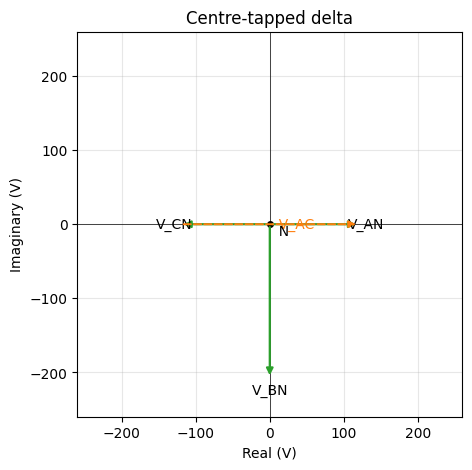

In [2]:
# Centre-tapped closed delta, 120/240 V.
V_AN = P(120, 0)

V_CN = -V_AN               # step 1: A, N and C are on one winding
V_AC = V_AN - V_CN         # step 2: route A -> N -> C  (V_AN + V_NC)
V_CA = -V_AC

V_AB = V_CA * P(1, -120)   # step 3: V_CA lags V_AB by 240°, so V_AB = V_CA rotated -120°
V_BC = V_AB * P(1, -120)   #         V_BC lags V_AB by 120°

V_BN = -V_AB + V_AN        # step 4: route B -> A -> N  (V_BA + V_AN)

show(V_CN=V_CN, V_AC=V_AC, V_AB=V_AB, V_BC=V_BC, V_CA=V_CA, V_BN=V_BN)
kirchhoff_check(V_AB, V_BC, V_CA)
plot_phasors(from_n={"V_AN": V_AN, "V_CN": V_CN, "V_BN": V_BN},
             tip_to_tip={"V_AC": (V_CN, V_AN)},
             title="Centre-tapped delta");